# Stroke detection + 30-bin discretisation

Runs on the **cleaned 6-DoF IMU output** of `preprocessing.ipynb` (`t_s, ax..az_mps2, gx..gz_rads`).

Mirrors the Slade et al. gait methodology (`estimation.py`), with heel strikes replaced by rowing catches:

| Slade (walking) | here (erg) |
|---|---|
| shank gyro-z, low-pass 6 Hz | gyro projected on its dominant rotation axis (PC1), low-pass 3 Hz — placement independent |
| `find_peaks`, fixed 70 deg/s height, 0.6 s min distance | `find_peaks`, prominence relative to the signal range, min distance = 0.6 × stroke period (from autocorrelation) |
| gait cycle = heel strike → next heel strike | stroke = **catch → next catch** (zero crossing into the drive) |
| `signal.resample(cycle, 30)` | `signal.resample(stroke, 30)` (also `"interp"` / `"mean"` options) |
| flatten `[features × bins]`, prepend `[1, weight, height]` | same ordering, 6 × 30 = 180 features (+ weight/height) |

The drive is faster than the recovery, so the detection signal is signed so the drive is positive. Each drive peak is one stroke, and the catch is the reversal (zero crossing) just before it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import imu_preprocessing as ip
import stroke_detection as sd

CLEAN_DIR = Path("../test data/imu_clean")   # output of preprocessing.ipynb
OUT_DIR = Path("../test data/strokes")
N_BINS = 30
BIN_METHOD = "resample"   # Slade; or "interp" / "mean"
files = sorted(CLEAN_DIR.glob("*.csv"))
files

[PosixPath('../test data/imu_clean/20261105-142707_test_t02.csv')]

## 1. Sanity check on synthetic erg data
Real erg recordings aren't in yet (the file in `test data/imu` is generic test IMU data), so first check the detector against simulated thigh-IMU rowing with **known catch times**: random sensor orientation, stroke rate ramping 18 → 34 spm, drive ≈ 0.8 s.

{'fs': 100.00000000000213, 'channel': 'gyro PC1 axis [-0.24, 0.9, 0.37]', 'sign': -1, 'event': 'catch', 'est_rate_spm': np.float64(28.43601895734658)}
38/39 true catches detected (the last one's drive is cut off by the end of the recording); timing error -15.6 ± 9.3 ms


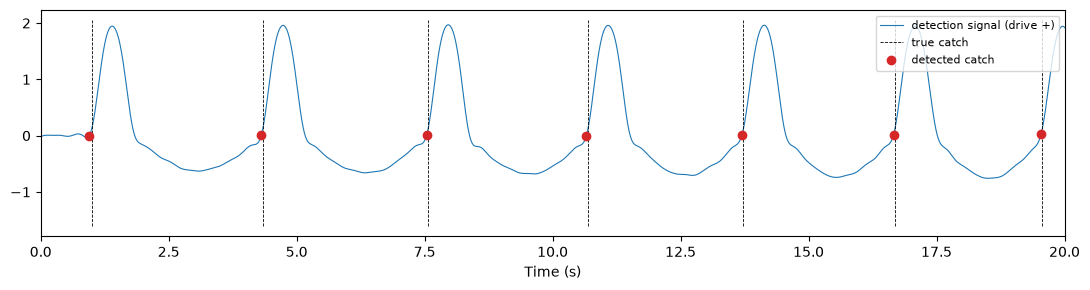

In [2]:
sim, true_catches = sd.simulate_erg_imu(duration_s=90, spm=(18, 34), seed=1)
sim_clean, _ = ip.clean_imu(sim)
sim_strokes, sim_x = sd.detect_strokes(sim_clean, return_signal=True)

det = np.r_[sim_strokes.t_start.to_numpy(), sim_strokes.t_end.iloc[-1]]
err = np.array([det[np.argmin(abs(det - c))] - c for c in true_catches])
matched = abs(err) < 0.2
print(sim_strokes.attrs)
print(f"{matched.sum()}/{len(true_catches)} true catches detected "
      f"(the last one's drive is cut off by the end of the recording); "
      f"timing error {1e3*err[matched].mean():.1f} ± {1e3*err[matched].std():.1f} ms")

fig, ax = plt.subplots(figsize=(11, 3))
t = sim_clean.t_s
ax.plot(t, sim_x, lw=0.8, label="detection signal (drive +)")
ax.vlines(true_catches, sim_x.min(), sim_x.max(), color="k", lw=0.6, ls="--", label="true catch")
ax.plot(t.iloc[sim_strokes.start_idx], sim_x[sim_strokes.start_idx], "o", color="C3", label="detected catch")
ax.set_xlim(0, 20); ax.set_xlabel("Time (s)"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()

## 2. Detect strokes in a cleaned recording

In [3]:
path = files[0]
clean = pd.read_csv(path)
strokes, x = sd.detect_strokes(clean, event="catch", return_signal=True)
print(path.name, strokes.attrs)
print(f"{len(strokes)} strokes, {strokes.valid.sum()} valid, "
      f"median rate {strokes.loc[strokes.valid, 'rate_spm'].median():.1f} spm")
strokes

20261105-142707_test_t02.csv {'fs': 100.00000000000213, 'channel': 'gyro PC1 axis [-0.07, -1.0, 0.01]', 'sign': 1, 'event': 'catch', 'est_rate_spm': np.float64(41.37931034482847)}
9 strokes, 8 valid, median rate 43.0 spm


,start_idx,end_idx,t_start,t_end,duration_s,peak_idx,rate_spm,valid
0,92,209,0.92,2.09,1.17,116,51.282051,True
1,209,349,2.09,3.49,1.40,238,42.857143,True
2,349,506,3.49,5.06,1.57,376,38.216561,True
3,506,669,5.06,6.69,1.63,534,36.809816,True
4,669,767,6.69,7.67,0.98,690,61.224490,True
5,767,949,7.67,9.49,1.82,850,32.967033,True
6,949,1503,9.49,15.03,5.54,967,10.830325,False
7,1503,1636,15.03,16.36,1.33,1517,45.112782,True
8,1636,1775,16.36,17.75,1.39,1661,43.165468,True


In [ ]:
t = clean.t_s.to_numpy()
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(t, x, lw=0.8, color="k")
axes[0].plot(t[strokes.peak_idx], x[strokes.peak_idx], "^", color="C1", label="drive peak")
axes[0].set_ylabel("detection\nsignal"); axes[0].legend(fontsize=8, loc="upper right")
for ax, cols, unit in zip(axes[1:], [ip.ACC, ip.GYR], ["m/s²", "rad/s"]):
    for c in cols:
        ax.plot(t, clean[c], lw=0.8, label=c)
    ax.set_ylabel(unit); ax.legend(fontsize=8, loc="upper right", ncol=3)
for ax in axes:
    for _, s in strokes.iterrows():
        ax.axvline(s.t_start, color="C2" if s.valid else "C3", lw=0.8, alpha=0.7)
axes[0].set_title("Stroke boundaries (green = valid, red = rejected)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()

## 3. Split each stroke into 30 bins
`binned` is `[n_strokes × 30 × 6]`. Each stroke is time-normalised (0 % = catch, 100 % = next catch), regardless of its duration or stroke rate.

In [ ]:
binned, used = sd.bin_strokes(clean, strokes, n_bins=N_BINS, method=BIN_METHOD)
print("binned:", binned.shape)

pct = np.arange(N_BINS) / N_BINS * 100
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
for j, (ax, c) in enumerate(zip(axes.flat, ip.SIGNALS)):
    ax.plot(pct, binned[:, :, j].T, color="0.7", lw=0.6)
    m, s = binned[:, :, j].mean(0), binned[:, :, j].std(0)
    ax.plot(pct, m, color="C0", lw=2); ax.fill_between(pct, m - s, m + s, color="C0", alpha=0.2)
    ax.set_title(c, fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("% stroke (catch → catch)")
plt.suptitle(f"{len(binned)} strokes, {N_BINS} bins ({BIN_METHOD})")
plt.tight_layout()

## 4. Feature matrix (Slade ordering)
One row per stroke: `ax_mps2_b00 … ax_mps2_b29, ay_mps2_b00, …, gz_rads_b29` (= `[features × bins].flatten()`), with the rower's `weight` (kg) and `height` (m) prepended as in Slade's model input.

In [ ]:
WEIGHT_KG, HEIGHT_M = None, None   # fill in per subject
feats = sd.stroke_features(binned, weight=WEIGHT_KG, height=HEIGHT_M)
feats.insert(0, "t_start", used.t_start.values)
feats.insert(1, "rate_spm", used.rate_spm.values)
print(feats.shape)
feats.head()

## 5. Batch: every cleaned file → stroke table + 30-bin features

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary = []
for p in files:
    df = pd.read_csv(p)
    try:
        st, b, f = sd.segment_strokes(df, n_bins=N_BINS, method=BIN_METHOD)
    except ValueError as e:
        summary.append({"file": p.name, "error": str(e)}); continue
    v = st[st.valid]
    f.insert(0, "t_start", v.t_start.values); f.insert(1, "rate_spm", v.rate_spm.values)
    st.to_csv(OUT_DIR / f"{p.stem}_strokes.csv", index=False)
    f.to_csv(OUT_DIR / f"{p.stem}_bins{N_BINS}.csv", index=False)
    summary.append({"file": p.name, "strokes": len(st), "valid": int(st.valid.sum()),
                    "median_spm": round(v.rate_spm.median(), 1), "channel": st.attrs["channel"]})
summary = pd.DataFrame(summary)
summary